In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

In [24]:
#connect to duckdb
con = duckdb.connect("../Data/duckdb/olist.duckdb")

#Load CSV & Create Views
con.read_csv("../Data/Processed/orders_clean.csv").create_view("orders");

### Order Status Analysis

In [25]:
# Calculate the total number of orders
total = con.sql(""" 
    select count(*) as total
    from orders
 """).df()

print(f"Total orders: {total.iloc[0, 0]}")

Total orders: 99441


In [26]:
#check order status of orders
order_status = con.sql(""" 
        select order_status,
                count(*) as status_number,
                count(*) * 100.0 / sum(count(*)) over () as status_percent
        from orders
        group by order_status
        order by status_number desc;
 """).df()

print("number of each order_status:")
display(order_status)

number of each order_status:


,order_status,status_number,status_percent
0,delivered,96478,97.020344
1,shipped,1107,1.113223
2,canceled,625,0.628513
3,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
6,created,5,0.005028
7,approved,2,0.002011


In [27]:
con.close()

In [ ]:
#reconnect to duckdb
con = duckdb.connect("../Data/duckdb/olist.duckdb")

In [29]:
order_status

,order_status,status_number,status_percent
0,delivered,96478,97.020344
1,shipped,1107,1.113223
2,canceled,625,0.628513
3,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
6,created,5,0.005028
7,approved,2,0.002011


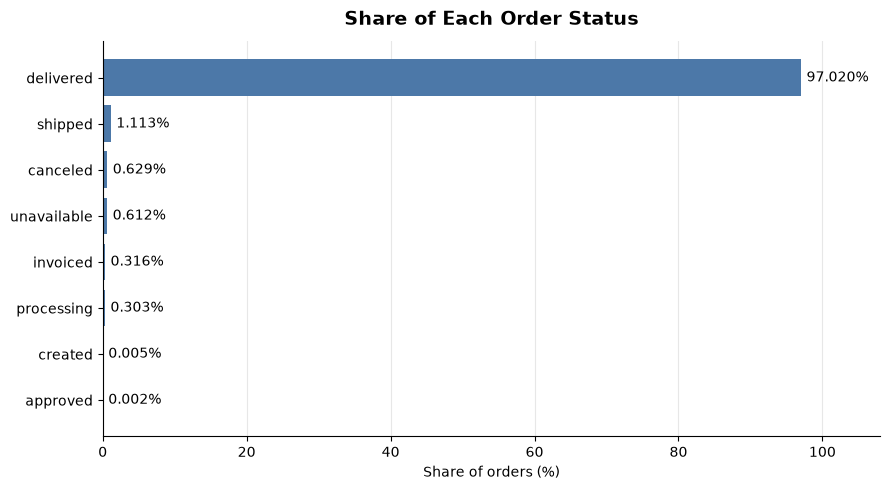

In [30]:
#visualizing chart
plot_df = order_status.sort_values("status_percent", ascending=True)  # ascending=True puts the largest bar on top

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(plot_df["order_status"], plot_df["status_percent"], color="#4C78A8")

ax.bar_label(bars, fmt="%.3f%%", padding=4, fontsize=10)

ax.set_title("Share of Each Order Status", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Share of orders (%)")
ax.set_ylabel("")
ax.set_xlim(0, 108)  # room so the 97.02% label isn't cut off
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Order Status Analysis – Conclusion

The Olist dataset contains **99,441 orders**, of which **97.02% (96,478)** were successfully delivered. Only **0.63%** were canceled, indicating a relatively low cancellation rate.

The remaining orders were distributed across other statuses, including shipped, unavailable, invoiced, and processing.

**Business Insight:**

Overall, Olist demonstrates a high order fulfillment rate and a relatively low cancellation rate. However, further investigation of non-delivered orders is needed to identify potential operational issues.

### Monthly Order Analysis

In [54]:
monthly_order = con.sql(""" 
    select order_month,
            count(*) as orders_count
    from orders
    group by order_month
    order by order_month
""").df()

#set month name
monthly_order["order_month_name"] = pd.to_datetime(monthly_order['order_month'], format='%m').dt.month_name()

print("number of orders for each month")
display(monthly_order[["order_month","order_month_name","orders_count"]])


#most and least month otders
max_month = monthly_order.loc[monthly_order["orders_count"].idxmax()]
min_month = monthly_order.loc[monthly_order["orders_count"].idxmin()]

print(
    f"Month with the most orders: {max_month['order_month_name']} "
    f"with {max_month['orders_count']} orders"
)
print(
    f"Month with the least orders: {min_month['order_month_name']} "
    f"with {min_month['orders_count']} orders"
)

number of orders for each month


,order_month,order_month_name,orders_count
0,1,January,8069
1,2,February,8508
2,3,March,9893
3,4,April,9343
4,5,May,10573
5,6,June,9412
6,7,July,10318
7,8,August,10843
8,9,September,4305
9,10,October,4959


Month with the most orders: August with 10843 orders
Month with the least orders: September with 4305 orders


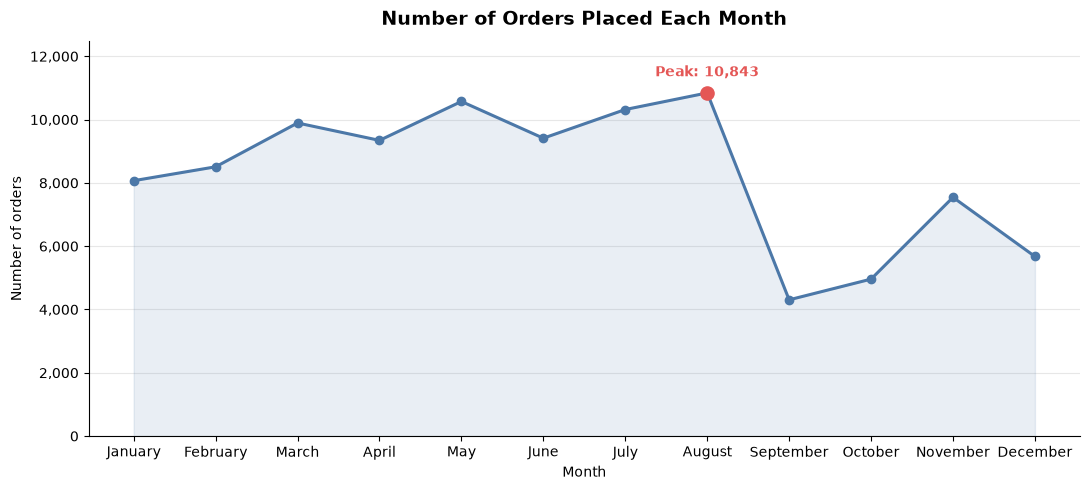

In [46]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    monthly_order["order_month_name"],
    monthly_order["orders_count"],
    marker="o",
    markersize=6,
    linewidth=2.2,
    color="#4C78A8",
)

# Light fill under the line
ax.fill_between(
    monthly_order["order_month_name"],
    monthly_order["orders_count"],
    alpha=0.12,
    color="#4C78A8",
)

# Highlight the peak month
peak = monthly_order.loc[monthly_order["orders_count"].idxmax()]
ax.scatter(peak["order_month_name"], peak["orders_count"], color="#E45756", s=90, zorder=5)
ax.annotate(
    f"Peak: {peak['orders_count']:,}",
    (peak["order_month_name"], peak["orders_count"]),
    textcoords="offset points",
    xytext=(0, 12),
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#E45756",
)

ax.set_title("Number of Orders Placed Each Month", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Month")
ax.set_ylabel("Number of orders")
ax.set_ylim(0, monthly_order["orders_count"].max() * 1.15)  # room for the peak label
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()